# Housing Price Prediction

Questo notebook guida attraverso tutte le fasi per predire il prezzo delle case usando tecniche di regressione.

## 1. Import Required Libraries

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## 2. Load and Explore Housing Dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

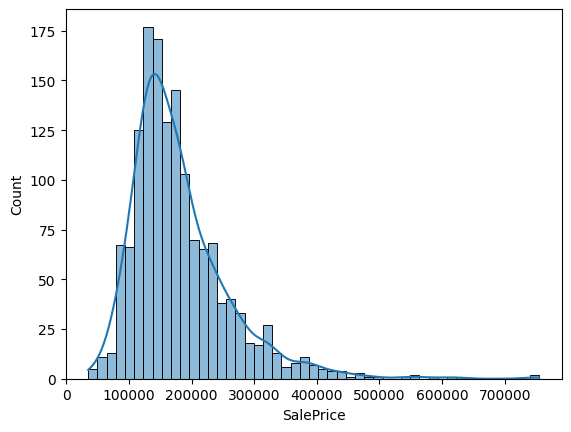

In [10]:
# Carica i dati delle case
housing_df = pd.read_csv('../data/train.csv')
housing_df.head()
housing_df.info()
housing_df.describe()
sns.histplot(housing_df['SalePrice'], kde=True)
plt.show()

## 3. Preprocess Data

In [11]:
# Gestione valori mancanti e encoding
for col in housing_df.select_dtypes(include=['object']).columns:
    housing_df[col].fillna(housing_df[col].mode()[0], inplace=True)
    housing_df[col] = LabelEncoder().fit_transform(housing_df[col])
for col in housing_df.select_dtypes(include=['float', 'int']).columns:
    housing_df[col].fillna(housing_df[col].median(), inplace=True)
scaler = StandardScaler()
housing_df[housing_df.select_dtypes(include=['float', 'int']).columns] = scaler.fit_transform(housing_df.select_dtypes(include=['float', 'int']))

/tmp/ipykernel_7199/240476725.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  housing_df[col].fillna(housing_df[col].mode()[0], inplace=True)
/tmp/ipykernel_7199/240476725.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace

## 4. Split Data into Training and Test Sets

In [12]:
# Suddividi in train e test
X = housing_df.drop('SalePrice', axis=1)
y = housing_df['SalePrice']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 5. Train Regression Model

In [13]:
# Addestra un modello di regressione lineare
model = LinearRegression()
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


## 6. Evaluate Model Performance

In [14]:
# Valuta le performance sul test set
preds = model.predict(X_test)
mse = mean_squared_error(y_test, preds)
r2 = r2_score(y_test, preds)
print(f'Mean Squared Error: {mse:.2f}')
print(f'R^2 Score: {r2:.2f}')

Mean Squared Error: 0.20
R^2 Score: 0.84


## 8. Make Predictions and Create Submission File

In [15]:
# Carica e preprocessa test.csv
new_df = pd.read_csv('../data/test.csv')
for col in new_df.select_dtypes(include=['object']).columns:
    new_df[col].fillna(new_df[col].mode()[0], inplace=True)
    new_df[col] = LabelEncoder().fit_transform(new_df[col])
for col in new_df.select_dtypes(include=['float', 'int']).columns:
    new_df[col].fillna(new_df[col].median(), inplace=True)
scaler = StandardScaler()
new_df[new_df.select_dtypes(include=['float', 'int']).columns] = scaler.fit_transform(new_df.select_dtypes(include=['float', 'int']))

# Allinea le colonne con quelle usate nel training
X_new = new_df[X_train.columns]
predictions = model.predict(X_new)
submission = pd.DataFrame({
    'Id': new_df['Id'] if 'Id' in new_df.columns else range(1, len(new_df)+1),
    'SalePrice': predictions
})
submission.to_csv('../data/submission.csv', index=False)
submission.head()

/tmp/ipykernel_7199/2151946298.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  new_df[col].fillna(new_df[col].mode()[0], inplace=True)
/tmp/ipykernel_7199/2151946298.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)

,Id,SalePrice
0,-1.730864,-0.845587
1,-1.728490,-0.091380
2,-1.726115,-0.114583
3,-1.723741,0.126963
4,-1.721367,0.112786
